# Chapitre 9 - Cours 6 : les services de coordination

Implémenter soi-même un algorithme de consensus est une très mauvaise idée : les cours
précédents ont montré combien les détails comptent. La plupart des systèmes distribués
**sous-traitent** donc le consensus à un **service de coordination** : ZooKeeper, etcd ou
Consul. Ce notebook modélise un tel service (`cs.CoordService` : révisions, baux, clés
éphémères et séquentielles, surveillances) et l'utilise pour les usages du livre : verrous
et baux avec jetons de clôture, détection de pannes, élection de leader, répartition du
travail entre nœuds, découverte de services. Il couvre la section *Membership and Coordination Services* (*Allocating work to nodes*, *Service discovery*, *Membership services*).

**Plan.**

1. Ce qu'est un service de coordination.
2. Verrous, baux et jetons de clôture.
3. Détection de pannes : sessions et clés éphémères.
4. Notifications et élection de leader.
5. Répartir le travail entre les nœuds.
6. Découverte de services.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Ce qu'est un service de coordination (section *Membership and Coordination Services*)

Vu de loin, ZooKeeper ou etcd ressemblent à un magasin clé-valeur. Mais ils ne sont pas
faits pour stocker des données volumineuses ou absorber un fort débit d'écritures : ils
servent à **coordonner les nœuds d'un autre système distribué**. Ils gardent une petite
quantité de données, qui tient en mémoire (tout en étant écrite sur disque pour la
durabilité), répliquée sur quelques nœuds par un algorithme de consensus tolérant aux
pannes (Zab pour ZooKeeper, Raft pour etcd). Ils s'inspirent du service de verrous
**Chubby** de Google. HBase, Kafka ou Hadoop YARN, par exemple, s'appuient sur ZooKeeper.

Au consensus (qui fournit des opérations linéarisables, dont le CAS), ils ajoutent des
fonctions très utiles pour construire des systèmes distribués :

- **verrous et baux** : si plusieurs nœuds tentent d'acquérir le même bail, un seul réussit ;
- **clôture** (fencing) : chaque écriture reçoit un identifiant croissant (zxid et
  cversion chez ZooKeeper, numéro de révision chez etcd), utilisable comme jeton ;
- **détection de pannes** : chaque client garde une **session** entretenue par des
  battements ; si la session expire, ses baux sont libérés et ses clés **éphémères**
  disparaissent ;
- **notifications** : un client peut **surveiller** (watch) une clé et être prévenu de ses
  changements, sans interroger le service en boucle.

La détection de pannes et les notifications ne demandent pas de consensus ; les
opérations atomiques et la clôture, si.

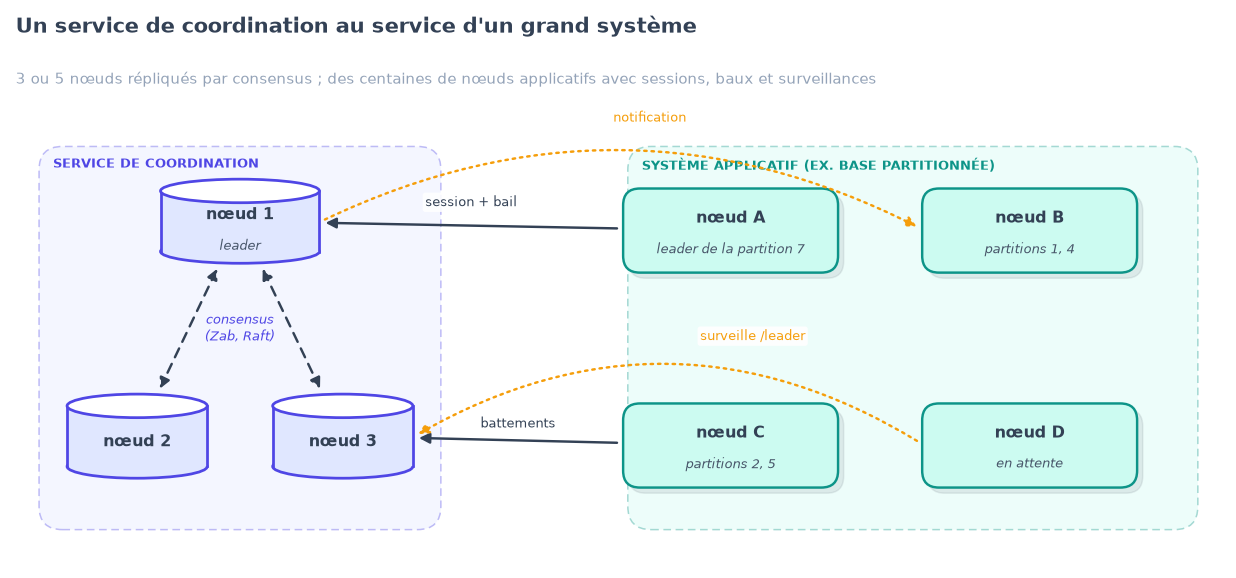

In [2]:
d = Diagram(13, 5.0, title="Un service de coordination au service d'un grand système",
            subtitle="3 ou 5 nœuds répliqués par consensus ; des centaines de nœuds applicatifs avec sessions, baux et surveillances")
d.group(0.3, 0.4, 4.6, 4.5, "service de coordination", color=INDIGO)
d.box("z1", 2.45, 3.7, "nœud 1", sub="leader", color=INDIGO, kind="db", w=1.7, h=0.9)
d.box("z2", 1.35, 1.4, "nœud 2", color=INDIGO, kind="db", w=1.5, h=0.9)
d.box("z3", 3.55, 1.4, "nœud 3", color=INDIGO, kind="db", w=1.5, h=0.9)
d.arrow("z1", "z2", style="dashed", both=True)
d.arrow("z1", "z3", style="dashed", both=True)
d.note(2.45, 2.55, "consensus\n(Zab, Raft)", color=INDIGO, fontsize=8.5)
d.group(6.6, 0.4, 12.7, 4.5, "système applicatif (ex. base partitionnée)", color=TEAL)
apps = [("a1", 7.7, 3.6, "nœud A", "leader de la partition 7"), ("a2", 10.9, 3.6, "nœud B", "partitions 1, 4"),
        ("a3", 7.7, 1.3, "nœud C", "partitions 2, 5"), ("a4", 10.9, 1.3, "nœud D", "en attente")]
for name, x, y, t, s in apps:
    d.box(name, x, y, t, sub=s, color=TEAL, w=2.3, h=0.9)
d.arrow("a1", "z1", "session + bail", label_offset=(0, 0.25))
d.arrow("a3", "z3", "battements")
d.arrow("z1", "a2", "notification", color=AMBER, style="dotted", rad=-0.25, label_offset=(0.3, 0.35))
d.arrow("a4", "z3", "surveille /leader", style="dotted", color=AMBER, rad=0.3, label_offset=(0.9, 0.3))
d.show()

> **À retenir.** Un service de coordination = un petit magasin clé-valeur linéarisable
> répliqué par consensus, plus des baux, des sessions, des clés éphémères, des
> identifiants croissants et des notifications. On l'utilise pour coordonner, pas pour
> stocker.